In [52]:

# AgentWeather - API Exploration
# Purpose: Explore weather API data for Karachi

import sys
import pandas as pd
import numpy as np
import matplotlib
import requests
from pathlib import Path

# Project paths
project_root = Path.cwd().parent

output_dir = project_root / "reports" / "eda"
output_dir.mkdir(parents=True, exist_ok=True)

print("Project root:", project_root)
print("EDA output directory:", output_dir)
print("Python Version:", sys.version)
print("Python Executable:", sys.executable)
print("Pandas Version:", pd.__version__)
print("NumPy Version:", np.__version__)
print("Matplotlib Version:", matplotlib.__version__)
print("Requests Version:", requests.__version__)

Project root: /home/musman/Desktop/ShinePearl/AgentWeather
EDA output directory: /home/musman/Desktop/ShinePearl/AgentWeather/reports/eda
Python Version: 3.11.18 (main, Oct 26 2026, 18:19:35) [GCC 14.3.0]
Python Executable: /home/musman/anaconda3/envs/agentweather/bin/python
Pandas Version: 3.1.1
NumPy Version: 2.4.6
Matplotlib Version: 3.11.2
Requests Version: 2.34.2


In [53]:
url = "https://api.open-meteo.com/v1/forecast"

params = {
    "latitude": 24.86,
    "longitude": 67.01,
    "hourly": "uv_index,is_day",
    "timezone": "UTC",
    "forecast_days": 2,
}

response = requests.get(url, params=params, timeout=30)

response.raise_for_status()

data = response.json()

print("API request successful!")
print(data.keys())

API request successful!
dict_keys(['latitude', 'longitude', 'generationtime_ms', 'utc_offset_seconds', 'timezone', 'timezone_abbreviation', 'elevation', 'hourly_units', 'hourly'])


In [54]:
print("Available hourly variables:")
print(data["hourly"].keys())

print("\nFirst 5 timestamps:")
print(data["hourly"]["time"][:5])

print("\nFirst 5 UV index values:")
print(data["hourly"]["uv_index"][:5])

print("\nFirst 5 day/night indicators:")
print(data["hourly"]["is_day"][:5])

Available hourly variables:
dict_keys(['time', 'uv_index', 'is_day'])

First 5 timestamps:
['2026-11-26T00:00', '2026-11-26T01:00', '2026-11-26T02:00', '2026-11-26T03:00', '2026-11-26T04:00']

First 5 UV index values:
[0.0, 0.0, 0.0, 0.3, 1.3]

First 5 day/night indicators:
[0, 0, 1, 1, 1]


In [55]:
df = pd.DataFrame(data["hourly"])

df["time"] = pd.to_datetime(df["time"], utc=True)

df = df.set_index("time")

df.head()

,uv_index,is_day
time,,
2026-11-26 00:00:00+00:00,0.0,0
2026-11-26 01:00:00+00:00,0.0,0
2026-11-26 02:00:00+00:00,0.0,1
2026-11-26 03:00:00+00:00,0.3,1
2026-11-26 04:00:00+00:00,1.3,1


In [56]:
df.info()

<class 'pandas.DataFrame'>
DatetimeIndex: 48 entries, 2026-11-26 00:00:00+00:00 to 2026-11-27 23:00:00+00:00
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   uv_index  48 non-null     float64
 1   is_day    48 non-null     int64  
dtypes: float64(1), int64(1)
memory usage: 1.1 KB


In [57]:
df.isnull().sum()

uv_index    0
is_day      0
dtype: int64

In [58]:
df.describe()

,uv_index,is_day
count,48.000000,48.000000
mean,1.191667,0.458333
std,1.744332,0.503534
min,0.000000,0.000000
25%,0.000000,0.000000
50%,0.000000,0.000000
75%,2.262500,1.000000
max,4.900000,1.000000


Plot saved successfully!


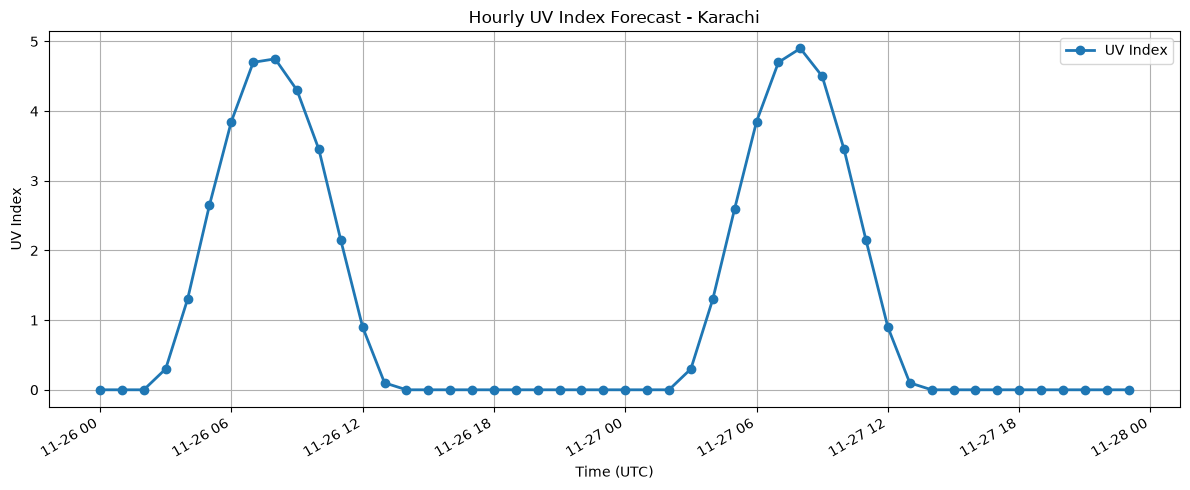

In [59]:

import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(
    df.index,
    df["uv_index"],
    marker="o",
    linewidth=2,
    label="UV Index"
)

ax.set_title("Hourly UV Index Forecast - Karachi")
ax.set_xlabel("Time (UTC)")
ax.set_ylabel("UV Index")

ax.grid(True)
ax.legend()

fig.autofmt_xdate()
fig.tight_layout()

fig.savefig(
    output_dir / "uv_index_karachi.png",
    dpi=150,
    bbox_inches="tight"
)

print("Plot saved successfully!")

plt.show()

In [60]:
# Expanded weather API request

weather_params = {
    "latitude": 24.86,
    "longitude": 67.01,
    "hourly": (
        "temperature_2m,"
        "relative_humidity_2m,"
        "precipitation,"
        "precipitation_probability,"
        "wind_speed_10m,"
        "wind_direction_10m,"
        "uv_index,"
        "is_day"
    ),
    "temperature_unit": "celsius",
    "wind_speed_unit": "kmh",
    "precipitation_unit": "mm",
    "timezone": "UTC",
    "forecast_days": 2,
}

weather_response = requests.get(
    url,
    params=weather_params,
    timeout=30
)

weather_response.raise_for_status()

weather_data = weather_response.json()

print("Expanded weather API request successful!")
print("Available sections:", weather_data.keys())

Expanded weather API request successful!
Available sections: dict_keys(['latitude', 'longitude', 'generationtime_ms', 'utc_offset_seconds', 'timezone', 'timezone_abbreviation', 'elevation', 'hourly_units', 'hourly'])


In [61]:
print("Available hourly variables")
print(weather_data["hourly"].keys())

print("\nUnits of each variables")
print(weather_data["hourly_units"])

Available hourly variables
dict_keys(['time', 'temperature_2m', 'relative_humidity_2m', 'precipitation', 'precipitation_probability', 'wind_speed_10m', 'wind_direction_10m', 'uv_index', 'is_day'])

Units of each variables
{'time': 'iso8601', 'temperature_2m': '°C', 'relative_humidity_2m': '%', 'precipitation': 'mm', 'precipitation_probability': '%', 'wind_speed_10m': 'km/h', 'wind_direction_10m': '°', 'uv_index': '', 'is_day': ''}


In [63]:
hourly_data = weather_data["hourly"]

print("Number of timestamps:", len(hourly_data["time"]))

for column, values in hourly_data.items():
    print(f"{column}: {len(values)} values")


Number of timestamps: 48
time: 48 values
temperature_2m: 48 values
relative_humidity_2m: 48 values
precipitation: 48 values
precipitation_probability: 48 values
wind_speed_10m: 48 values
wind_direction_10m: 48 values
uv_index: 48 values
is_day: 48 values


In [65]:
weather_df = pd.DataFrame(weather_data["hourly"])

# Convert time strings into proper UTC datetime values
weather_df["time"] = pd.to_datetime(
    weather_df["time"],
    utc=True
)

# Use time as the DataFrame index
weather_df = weather_df.set_index("time")

# Display the first 5 records

weather_df.head()

,temperature_2m,relative_humidity_2m,precipitation,precipitation_probability,wind_speed_10m,wind_direction_10m,uv_index,is_day
time,,,,,,,,
2026-11-26 00:00:00+00:00,19.4,92,0.0,0,5.1,4,0.0,0
2026-11-26 01:00:00+00:00,19.1,92,0.0,0,5.1,8,0.0,0
2026-11-26 02:00:00+00:00,18.9,92,0.0,0,4.4,19,0.0,1
2026-11-26 03:00:00+00:00,19.8,86,0.0,0,4.0,21,0.3,1
2026-11-26 04:00:00+00:00,22.6,73,0.0,0,3.8,17,1.3,1


In [66]:
weather_df.info()

<class 'pandas.DataFrame'>
DatetimeIndex: 48 entries, 2026-11-26 00:00:00+00:00 to 2026-11-27 23:00:00+00:00
Data columns (total 8 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   temperature_2m             48 non-null     float64
 1   relative_humidity_2m       48 non-null     int64  
 2   precipitation              48 non-null     float64
 3   precipitation_probability  48 non-null     int64  
 4   wind_speed_10m             48 non-null     float64
 5   wind_direction_10m         48 non-null     int64  
 6   uv_index                   48 non-null     float64
 7   is_day                     48 non-null     int64  
dtypes: float64(4), int64(4)
memory usage: 3.4 KB


In [67]:
weather_df.isnull().sum()

temperature_2m               0
relative_humidity_2m         0
precipitation                0
precipitation_probability    0
wind_speed_10m               0
wind_direction_10m           0
uv_index                     0
is_day                       0
dtype: int64

In [68]:
# Check timestamp ordering
print("Timestamps are sorted:", weather_df.index.is_monotonic_increasing)

# Check duplicate timestamps
print("Duplicate timestamps:", weather_df.index.duplicated().sum())

# Check missing values
print("\nMissing values:")
print(weather_df.isnull().sum())

# Check numerical statistics
print("\nStatistical summary:")
weather_df.describe()

Timestamps are sorted: True
Duplicate timestamps: 0

Missing values:
temperature_2m               0
relative_humidity_2m         0
precipitation                0
precipitation_probability    0
wind_speed_10m               0
wind_direction_10m           0
uv_index                     0
is_day                       0
dtype: int64

Statistical summary:


,temperature_2m,relative_humidity_2m,precipitation,precipitation_probability,wind_speed_10m,wind_direction_10m,uv_index,is_day
count,48.000000,48.000000,48.0,48.0,48.000000,48.000000,48.000000,48.000000
mean,23.543750,78.083333,0.0,0.0,6.279167,186.041667,1.191667,0.458333
std,3.058431,14.627042,0.0,0.0,2.401946,131.166446,1.744332,0.503534
min,18.900000,51.000000,0.0,0.0,0.900000,4.000000,0.000000,0.000000
25%,20.750000,64.000000,0.0,0.0,4.775000,18.500000,0.000000,0.000000
50%,23.300000,80.500000,0.0,0.0,5.950000,218.500000,0.000000,0.000000
75%,26.400000,92.000000,0.0,0.0,7.525000,301.500000,2.262500,1.000000
max,28.400000,96.000000,0.0,0.0,11.600000,360.000000,4.900000,1.000000


In [69]:
# Count unique values in each column
unique_counts = weather_df.nunique()

print("Unique values per column:")
print(unique_counts)

# Identify columns with only one unique value
constant_columns = unique_counts[unique_counts == 1]

print("\nConstant columns:")
print(constant_columns)

Unique values per column:
temperature_2m               43
relative_humidity_2m         30
precipitation                 1
precipitation_probability     1
wind_speed_10m               35
wind_direction_10m           44
uv_index                     15
is_day                        2
dtype: int64

Constant columns:
precipitation                1
precipitation_probability    1
dtype: int64


Plot saved successfully: /home/musman/Desktop/ShinePearl/AgentWeather/reports/eda/weather_overview_karachi.png


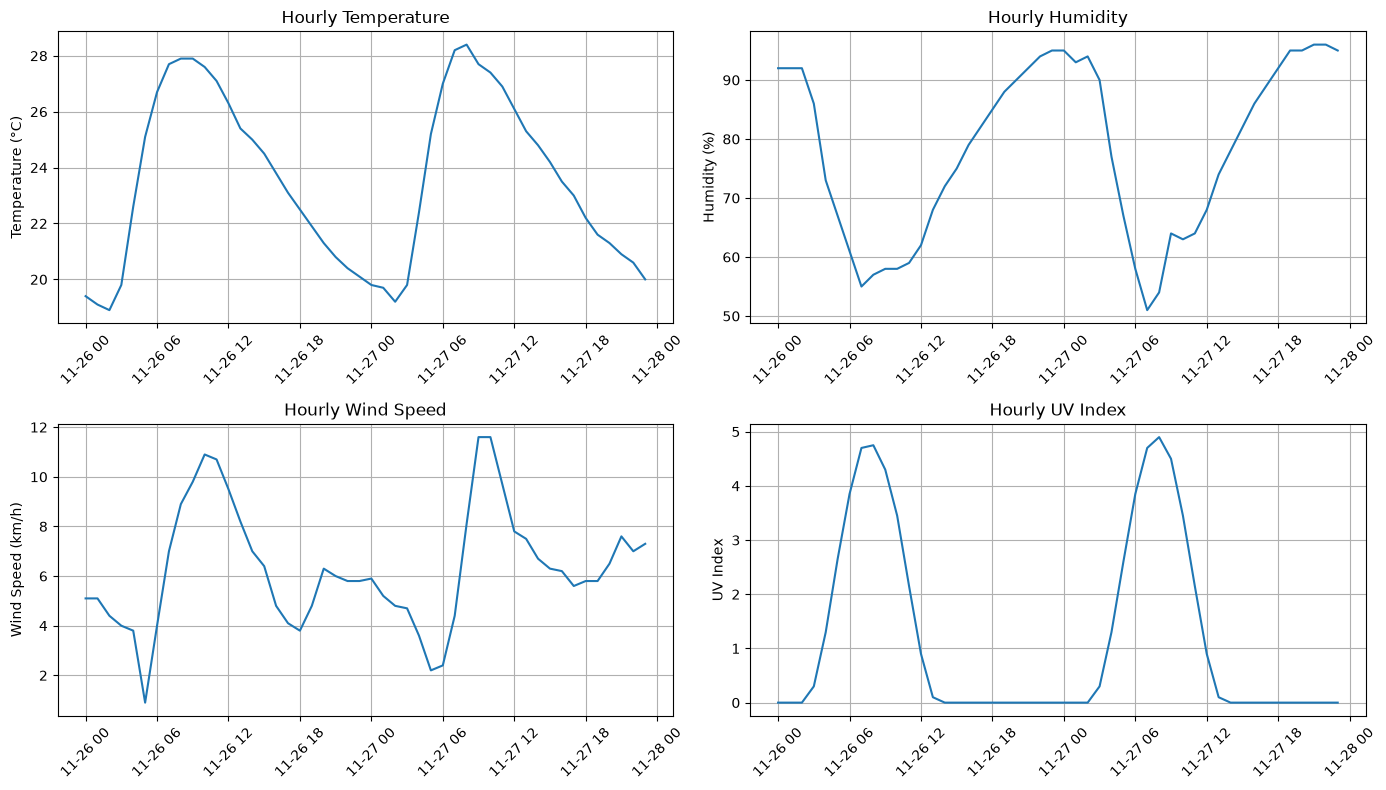

In [71]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 2, figsize=(14, 8))

# Temperature
axes[0, 0].plot(weather_df.index, weather_df["temperature_2m"])
axes[0, 0].set_title("Hourly Temperature")
axes[0, 0].set_ylabel("Temperature (°C)")

# Humidity
axes[0, 1].plot(weather_df.index, weather_df["relative_humidity_2m"])
axes[0, 1].set_title("Hourly Humidity")
axes[0, 1].set_ylabel("Humidity (%)")

# Wind speed
axes[1, 0].plot(weather_df.index, weather_df["wind_speed_10m"])
axes[1, 0].set_title("Hourly Wind Speed")
axes[1, 0].set_ylabel("Wind Speed (km/h)")

# UV index
axes[1, 1].plot(weather_df.index, weather_df["uv_index"])
axes[1, 1].set_title("Hourly UV Index")
axes[1, 1].set_ylabel("UV Index")

for ax in axes.flat:
    ax.tick_params(axis="x", rotation=45)
    ax.grid(True)

plt.tight_layout()

# Save the existing EDA visualization
plot_path = output_dir / "weather_overview_karachi.png"

fig.savefig(
    plot_path,
    dpi=150,
    bbox_inches="tight"
)

print(f"Plot saved successfully: {plot_path}")
plt.show()